# 01 · Course Introduction & Setup

**Module 01 — Python Foundations for Data Science**

---

## What you will learn

1. What a data scientist actually does day to day, and which parts of the job this course covers.
2. The data science lifecycle — and why it is a loop, not a pipeline.
3. How to set up a **reproducible** Python environment, and why that is a professional requirement rather than a nicety.
4. How to work in Jupyter without falling into its two classic traps.
5. A first end-to-end taste: data in, insight out.

**Estimated time:** 60 minutes

## 1. What is a data scientist, really?

The job title covers a wide range, but in a mid-to-large company the work almost
always decomposes into four recurring activities:

| Activity | What it looks like | Share of time |
| :--- | :--- | :-- |
| **Framing** | Turning a vague business request ("can we reduce churn?") into a measurable question with a defined success metric | ~15% |
| **Data work** | Finding, joining, cleaning, and validating data; discovering that a column changed meaning in March | ~50% |
| **Modelling & analysis** | Statistics, experiments, machine learning — the part that gets taught, and the smallest slice | ~20% |
| **Delivery** | Shipping the model, writing the readout, convincing a stakeholder, monitoring what you shipped | ~15% |

> [!NOTE]
> That 50% figure is not a sign of a badly run team — it is the job. A course that
> only teaches modelling prepares you for 20% of your work. This one covers all four.

### The three roles you will hear about

Titles vary between companies, but responsibilities cluster into three shapes:

- **Data Analyst** — describes what *happened*. SQL, dashboards, descriptive statistics.
- **Data Scientist** — explains *why* it happened and predicts what *will* happen. Statistics, experimentation, ML.
- **ML Engineer** — makes the prediction *run reliably* for millions of users. Engineering, pipelines, serving, monitoring.

The boundaries are blurry and moving. The market increasingly expects a data
scientist to be credible in all three columns — which is exactly what "full stack"
in this course's title means.

## 2. The data science lifecycle

Nearly every project follows the same loop. The single most important thing to
internalise: **the arrows go backwards too.**

You will discover during modelling (stage 6) that a feature is leaking, and go
back to stage 5. You will present results (stage 8) and learn the business
question was subtly different, sending you to stage 1. That is normal and expected —
it is not a sign that you planned badly.

![The data science lifecycle](../../../assets/images/ds_lifecycle.png)

### The stages, concretely

| Stage | Typical question | You will learn this in |
| :--- | :--- | :--- |
| 1. Business understanding | "What decision will this change?" | Modules 09, 24 |
| 2. Data collection | "Where does this live, and can I trust it?" | Modules 05, 20 |
| 3. Cleaning & preparation | "What do the missing values *mean*?" | Modules 03, 10 |
| 4. Exploratory data analysis | "What does the data actually look like?" | Modules 04, 06 |
| 5. Feature engineering | "What representation makes the signal learnable?" | Module 10 |
| 6. Modelling | "Which model, and with what hyperparameters?" | Modules 11–19 |
| 7. Evaluation | "Is this better than the current approach? By how much, and how sure am I?" | Modules 08, 13 |
| 8. Deployment & monitoring | "Is it still working three months later?" | Modules 21–23 |

## 3. Reproducibility: the environment

### Why virtual environments are non-negotiable

Imagine two projects on your laptop. Project A was built against `pandas 1.5`;
project B needs `pandas 3.0`, where several behaviours changed. With a single
system-wide Python installation you can only satisfy one of them.

A **virtual environment** is an isolated directory with its own Python
interpreter and its own installed packages. One per project. They are cheap,
disposable, and they eliminate an entire category of "works on my machine" bugs.

```text
CoursePythonStatistics/
└── .venv/                     ← this project's isolated environment
    ├── bin/python             ← its own interpreter
    └── lib/python3.12/site-packages/
                               ← its own packages, invisible to other projects
```

> [!WARNING]
> Never `pip install` into your system Python. On macOS and Linux you can break
> operating-system tooling that depends on it.

### The three levels of reproducibility

Professional teams distinguish between them, and you should too:

| Level | Mechanism | Guarantees |
| :--- | :--- | :--- |
| **1. Loose** | `pandas` | "Some version of pandas." Reproduces almost nothing. |
| **2. Constrained** | `pandas>=2.2,<3` | Reproduces the *API*. This is what `pyproject.toml` declares. |
| **3. Pinned** | `pandas==3.0.5` | Reproduces the *exact bits*. This is what `requirements-lock.txt` captures. |

The convention: humans edit level 2, machines generate level 3, and production
deploys from level 3.

### Verify your own environment

Run the cell below. It should report the interpreter living inside `.venv`.
If it reports a system path such as `/usr/bin/python3`, your notebook is
attached to the wrong kernel — fix it via the kernel picker in the top-right
before continuing, or nothing later in this course will import correctly.

In [1]:
import sys
from pathlib import Path

# `sys.executable` is the absolute path of the interpreter running this notebook.
# This is the ground truth — far more reliable than checking `which python` in a
# terminal, which tells you about your *shell*, not about this kernel.
print(f"Interpreter : {sys.executable}")
print(f"Version     : {sys.version.split()[0]}")

# A virtual environment sets `sys.prefix` to its own root while leaving
# `sys.base_prefix` pointing at the original interpreter. When they differ,
# we are inside a venv.
in_venv = sys.prefix != sys.base_prefix
print(f"In a venv?  : {in_venv}")

if in_venv:
    print(f"Venv root   : {Path(sys.prefix).name}")

Interpreter : /Users/usuario/Desktop/CoursePythonStatistics/.venv/bin/python
Version     : 3.12.13
In a venv?  : True
Venv root   : .venv


### Making the course's helper package importable

This repository ships a small package, `dstoolkit`, in `src/`. It was installed
into the environment in *editable* mode (`pip install -e .`), which means the
import below picks up your local edits immediately — no reinstall needed.

Editable installs are the standard way professional projects let notebooks and
tests import shared project code without fragile `sys.path` hacks.

In [2]:
import dstoolkit
from dstoolkit import setup_plot_style

print(f"dstoolkit version : {dstoolkit.__version__}")
print(f"loaded from       : {Path(dstoolkit.__file__).parent}")

# Apply the course-wide matplotlib style. One call, and every figure in every
# notebook shares the same fonts, colours, and spacing.
setup_plot_style()
print("\nPlot style applied.")

dstoolkit version : 0.1.0
loaded from       : /Users/usuario/Desktop/CoursePythonStatistics/src/dstoolkit

Plot style applied.


## 4. Working in Jupyter without shooting yourself in the foot

### The mental model

A notebook is **not** a script. It is a long-running Python process (the *kernel*)
plus a document of cells you can send to it **in any order**. That flexibility is
what makes notebooks great for exploration — and it is also the source of both
classic notebook bugs.

### Trap 1 — Hidden state from out-of-order execution

The execution counter `[n]` to the left of each cell tells you the order cells
*actually ran*, which may have nothing to do with their order on the page.

```python
# Cell A, executed 1st
df = load_data()

# Cell B, executed 3rd
df = df[df["revenue"] > 0]      # ran twice → filtered twice

# Cell C, executed 2nd
print(len(df))                  # printed a number that no longer holds
```

**The fix**, and it is a habit worth building now: before you trust a result or
share a notebook, run **Kernel → Restart Kernel and Run All Cells**. If it fails,
your notebook was lying to you.

### Trap 2 — Notebooks are not a substitute for functions

A cell that is 200 lines long cannot be tested, reused, or reviewed. The
professional pattern is a **promotion loop**:

1. Explore interactively in a cell.
2. Once it works, wrap it in a function.
3. Once you need it twice, move the function into `src/dstoolkit/`.
4. Write a test for it.
5. Import it back into the notebook.

You will practise this loop in notebook 08 of this module.

### Magic commands worth knowing

Jupyter adds "magics" — commands prefixed with `%` (applies to one line) or `%%`
(applies to the whole cell). These carry most of the value.

**`%timeit`** runs a statement many times and reports a robust average. Reach
for it whenever you are choosing between two implementations — Module 03 uses it
to show why sets beat lists for membership tests.

In [3]:
%timeit sum(range(1000))

26 μs ± 4.69 μs per loop (mean ± std. dev. of 7 runs, 10,000 loops each)


**`%%time`** measures the whole cell exactly once. Use it for slow, one-off
operations where running them a thousand times would be absurd. It must be the
very first line of the cell.

In [4]:
%%time
total = sum(i**2 for i in range(1_000_000))
print(f"{total:,}")

333,332,833,333,500,000
CPU times: user 125 ms, sys: 4.68 ms, total: 130 ms
Wall time: 139 ms


Other magics you will use constantly:

| Magic | What it does |
| :--- | :--- |
| `%who` / `%whos` | List variables currently defined in the kernel — a quick way to spot hidden state |
| `%debug` | Drop into a post-mortem debugger after an exception |
| `%load_ext autoreload` + `%autoreload 2` | Re-import your `src/` modules automatically after you edit them |
| `!command` | Run a shell command, e.g. `!ls data/raw` |

> [!TIP]
> Add `%load_ext autoreload` and `%autoreload 2` to the top of any notebook where
> you are actively editing code in `src/`. Without it you must restart the kernel
> to see your changes.

## 5. A first end-to-end taste

Enough setup. Let us do a miniature version of the whole lifecycle in one screen:
generate data, explore it, and answer a question with a chart.

The scenario: an e-commerce team wants to know whether **customers acquired
through paid ads spend less than customers acquired organically** — a question
that comes up in essentially every consumer company.

Everything here will be covered properly later. For now, just watch the shape of
the workflow.

In [5]:
import numpy as np
import pandas as pd

# ---------------------------------------------------------------------------
# Stage 2: get some data. We simulate it so the notebook is fully self-contained
# and reproducible. A fixed seed means you see exactly the numbers we see.
# ---------------------------------------------------------------------------
rng = np.random.default_rng(seed=42)

N_CUSTOMERS = 2_000

# Two acquisition channels with genuinely different spending behaviour.
# We use a lognormal distribution because customer spend is right-skewed:
# most people spend a little, a few spend a lot. Module 07 covers why.
channel = rng.choice(["organic", "paid"], size=N_CUSTOMERS, p=[0.55, 0.45])

spend = np.where(
    channel == "organic",
    rng.lognormal(mean=4.30, sigma=0.55, size=N_CUSTOMERS),  # higher centre
    rng.lognormal(mean=4.05, sigma=0.60, size=N_CUSTOMERS),  # lower centre
)

customers = pd.DataFrame(
    {
        "customer_id": np.arange(1, N_CUSTOMERS + 1),
        "channel": channel,
        "spend_usd": spend.round(2),
    }
)

customers.head()

,customer_id,channel,spend_usd
0,1,paid,17.26
1,2,organic,121.44
2,3,paid,103.54
3,4,paid,39.36
4,5,organic,53.39


### Stage 4: exploratory data analysis

The first question about any dataset is always the same: *what is in it, and is
any of it obviously broken?*

In [6]:
print(f"Rows: {len(customers):,}   Columns: {customers.shape[1]}")
print(f"\nMissing values per column:\n{customers.isna().sum()}")
print(f"\nSpend summary by channel:")

# `groupby` splits the data by channel, then computes several statistics at once.
# Module 03 covers this pattern in depth — it is the workhorse of pandas.
summary = customers.groupby("channel")["spend_usd"].agg(
    n="count",
    mean="mean",
    median="median",
    std="std",
)
summary.round(2)

Rows: 2,000   Columns: 3

Missing values per column:
customer_id    0
channel        0
spend_usd      0
dtype: int64

Spend summary by channel:


,n,mean,median,std
channel,,,,
organic,1094,86.12,74.27,51.64
paid,906,70.59,58.70,47.92


> [!WARNING]
> Notice that the **mean is well above the median** in both groups. That is the
> signature of a right-skewed distribution, and it means the mean alone would
> give a misleading picture of a "typical" customer. Reporting only an average
> here is one of the most common analytical mistakes in industry.
> Module 06 covers when to use which measure of central tendency.

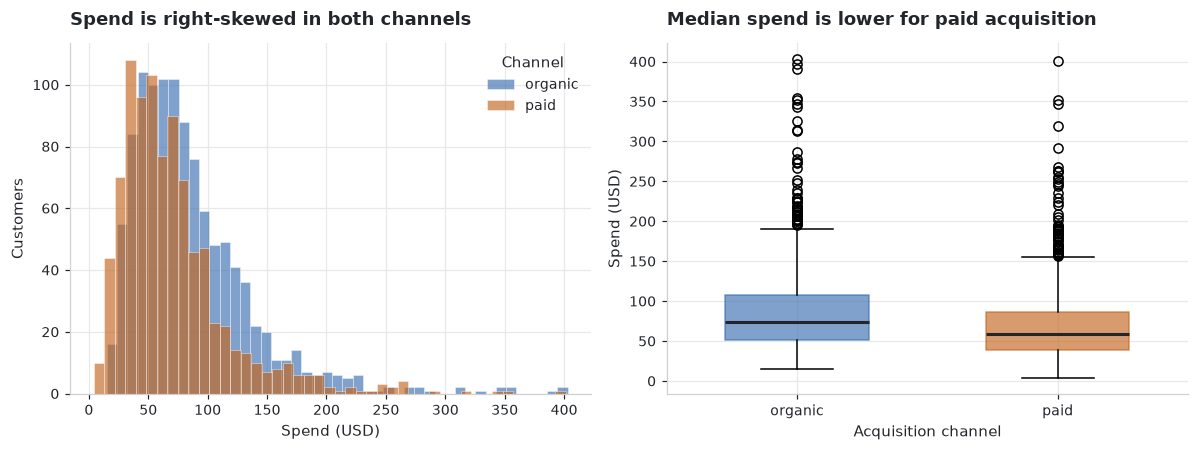

In [7]:
import matplotlib.pyplot as plt

from dstoolkit.plotting import COLORS

fig, (ax_hist, ax_box) = plt.subplots(1, 2, figsize=(11, 4.2))

# --- Left panel: the full distribution ---------------------------------------
# Overlapping histograms show the *shape* of spending, not just its centre.
channel_colors = {"organic": COLORS["primary"], "paid": COLORS["accent"]}

for name, group in customers.groupby("channel"):
    ax_hist.hist(
        group["spend_usd"],
        bins=45,
        alpha=0.65,
        label=name,
        color=channel_colors[name],
        edgecolor="white",
        linewidth=0.4,
    )

ax_hist.set_title("Spend is right-skewed in both channels")
ax_hist.set_xlabel("Spend (USD)")
ax_hist.set_ylabel("Customers")
ax_hist.legend(title="Channel")

# --- Right panel: a like-for-like comparison ---------------------------------
# A box plot compresses each distribution to its median and quartiles, which
# makes the comparison between groups much easier to read.
groups = ["organic", "paid"]
box_data = [customers.loc[customers["channel"] == c, "spend_usd"] for c in groups]

bp = ax_box.boxplot(
    box_data,
    tick_labels=groups,
    patch_artist=True,      # required for the boxes to accept a fill colour
    widths=0.55,
    medianprops={"color": COLORS["text"], "linewidth": 2},
)
for patch, name in zip(bp["boxes"], groups, strict=True):
    patch.set_facecolor(channel_colors[name])
    patch.set_alpha(0.65)
    patch.set_edgecolor(channel_colors[name])

ax_box.set_title("Median spend is lower for paid acquisition")
ax_box.set_ylabel("Spend (USD)")
ax_box.set_xlabel("Acquisition channel")

fig.tight_layout()
plt.show()

### Stage 7: what can we actually conclude?

The chart shows a difference. A professional's next question is immediately
*"is that difference real, or could it plausibly be noise?"*

That question — the difference between an observation and a **defensible claim** —
is the entire subject of Modules 07 and 08. Here is a preview of the answer:

In [8]:
from scipy import stats

organic = customers.loc[customers["channel"] == "organic", "spend_usd"]
paid = customers.loc[customers["channel"] == "paid", "spend_usd"]

# Welch's t-test: compares two means without assuming the groups share a
# variance. Module 08 explains the assumptions, and what to do when they fail.
t_stat, p_value = stats.ttest_ind(organic, paid, equal_var=False)

print(f"Organic mean : ${organic.mean():7.2f}   (n = {len(organic):,})")
print(f"Paid mean    : ${paid.mean():7.2f}   (n = {len(paid):,})")
print(f"Difference   : ${organic.mean() - paid.mean():7.2f}")
print(f"\nt-statistic  : {t_stat:.3f}")
print(f"p-value      : {p_value:.2e}")

Organic mean : $  86.12   (n = 1,094)
Paid mean    : $  70.59   (n = 906)
Difference   : $  15.53

t-statistic  : 6.963
p-value      : 4.52e-12


> [!NOTE]
> A small p-value says the observed gap is unlikely under the assumption that the
> two channels spend identically. It does **not** say paid ads *cause* lower
> spend — the channels differ in many ways at once. Separating correlation from
> causation is Module 09.

That is the whole loop in miniature: a question, some data, a look at its shape,
a quantified comparison, and an honest statement of what it does and does not
prove.

## 6. How this repository is organised

```text
CoursePythonStatistics/
├── pyproject.toml              ← dependency declarations (level 2)
├── requirements-lock.txt       ← exact pins (level 3)
├── assets/images/              ← generated diagrams
├── data/
│   ├── raw/                    ← immutable inputs; NEVER edit by hand
│   └── processed/              ← outputs of your notebooks
├── modules/01-python-foundations/
│   ├── notebooks/              ← the lessons
│   ├── scripts/                ← plain-text .py mirrors (readable diffs)
│   └── exercises/
├── src/dstoolkit/              ← shared, tested, importable code
└── tests/                      ← pytest suite for src/
```

### The one rule about `data/raw/`

**Raw data is immutable.** You never edit it, never overwrite it, never "just fix
that one bad row" in Excel. Every transformation is expressed as code that reads
from `raw/` and writes to `processed/`.

The reason is reproducibility: if the cleaning lives in code, anyone can rerun it
and get your numbers. If it lives in an undocumented manual edit, your results
can never be reproduced — including by you, in six months.

## 7. Exercises

> Work through these before moving to notebook 02. Solutions are in
> [`exercises/`](../exercises/).

### Exercise 1.1 — Environment audit

Write a cell that prints:
- the Python version, as a tuple of `(major, minor, micro)`;
- whether you are inside a virtual environment;
- the installed versions of `numpy`, `pandas`, and `matplotlib`.

*Hint:* every package exposes a `__version__` attribute.

### Exercise 1.2 — Reproduce the analysis with a different seed

Re-run the customer analysis with `seed=7` instead of `seed=42`.

- Do the group means change? By how much?
- Does the *conclusion* change?
- What does your answer tell you about how much to trust a single sample?

### Exercise 1.3 — Break the notebook deliberately

1. Run all cells in order.
2. Scroll up and re-run the cell that creates `customers`, but change `N_CUSTOMERS` to `50`.
3. Without re-running anything else, look at the `summary` variable.

Explain in one sentence what just happened, and name the menu command that
prevents this class of bug.

### Exercise 1.4 — Lifecycle mapping

Pick any data product you use (a recommendation feed, a fraud alert, a delivery
ETA). Write one sentence for each of the eight lifecycle stages describing what
the team behind it probably had to do.

## Key takeaways

- Data science is **50% data work**. The modelling is the small, visible tip.
- The lifecycle is a **loop**; going backwards is the process working, not failing.
- **Virtual environments are per-project and non-negotiable.** Declare loose
  constraints for humans, generate exact pins for machines.
- A notebook is a *long-running process*, not a script. **Restart & Run All**
  before you trust or share a result.
- Promote working code out of notebooks into a tested package.
- **Raw data is immutable.** Every transformation is code.

---

**Next:** [02 · Python Fundamentals](02_python_fundamentals.ipynb) — the object
model, and why `b = a` is one of the most misunderstood lines in Python.